# F1.1 — Figuras del análisis de potencia (adenda)

Figuras de apoyo de la tarea F1.1 (`docs/especificacion_f11.md`, `docs/bitacora/F1.1.md`). **No cambian resultados ni decisiones.**

Reglas que sigue este notebook:

- **Las cifras de las figuras 1 a 6 se leen de `results/f11_potencia/*.csv` y de `results/canonical_numbers.json`.** El notebook no recalcula ninguna cifra que vaya al reporte; solo filtra y ordena.
- **La figura 7 es ilustrativa.** Importa las funciones de `results/f11_potencia/potencia.py` sin reimplementarlas, usa una semilla fija (`SEMILLA_ILUSTRATIVA`) y se rotula «Simulación ilustrativa». Sus valores no son cifras del reporte.
- Notación de la especificación: $\delta(r) = (1-r)(F1_{BETO} - 0.5)$; $\theta = (\overline{F1}_{img} - 0.5) - r\,(F1_{BETO} - 0.5)$; $\rho$ es la retención verdadera.
- Estilo común de `src/viz/style.py`; exportación en PNG a 300 dpi a `results/f11_potencia/figures/`.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():          # nbconvert ejecuta desde notebooks/
    REPO = REPO.parent
sys.path[:0] = [str(REPO / 'src'), str(REPO / 'results' / 'f11_potencia'), str(REPO)]

from viz import style
import potencia as pot

style.apply()
RES = REPO / 'results' / 'f11_potencia'
FIG = RES / 'figures'

NUM = json.loads((REPO / 'results' / 'canonical_numbers.json').read_text(encoding='utf-8'))['numbers']
F1_BETO = NUM['ref.beto_exp41.f1_macro']['value']['test']
R_VALUES = (0.50, 0.75, 0.80)
DELTA = {r: NUM[f'f11.delta_margen.r{r:.2f}'.replace('0.', '0_')]['value']['test'] for r in R_VALUES}

MALLA = pd.read_csv(RES / 'malla_escenarios.csv')
EMP = pd.read_csv(RES / 'empirico.csv')
RMIN = pd.read_csv(RES / 'retencion_minima.csv')

# Colores: r en orden categórico fijo; veredictos en los cuatro primeros slots de la paleta de referencia
R_COLOR = {0.50: '#2a78d6', 0.75: '#eb6834', 0.80: '#1baf7a'}
R_MARKER = {0.50: 'o', 0.75: 's', 0.80: '^'}
V_COLOR = {'V1': '#2a78d6', 'V2': '#eb6834', 'V3': '#1baf7a', 'V4': '#eda100'}
V_LABEL = {'V1': 'V1 conservación', 'V2': 'V2 parcial', 'V3': 'V3 no conservación', 'V4': 'V4 no concluyente'}
CENTRAL = ('p50', 0.010)
DISC_LABEL = {'p10': 'discordancia p10', 'p50': 'discordancia p50', 'p90': 'discordancia p90'}

def central(df):
    return df[(df.disc_etiqueta == CENTRAL[0]) & np.isclose(df.de_objetivo, CENTRAL[1])]

print(f'F1_BETO (test) = {F1_BETO!r}')
print({f'r={r:.2f}': round(d, 4) for r, d in DELTA.items()})

F1_BETO (test) = 0.7038961038961039
{'r=0.50': 0.1019, 'r=0.75': 0.051, 'r=0.80': 0.0408}


## Figura 1 — Margen por retención del efecto

$F1_{BETO}$ y $\delta(r)$ se leen de `canonical_numbers.json` (`ref.beto_exp41.f1_macro`, `f11.delta_margen.*`). El umbral de cada fila es $F1_{BETO} - \delta(r) = 0.5 + r\,(F1_{BETO} - 0.5)$.

C:\Users\DELL\Desktop\TT\TT2\ttdicevc\results\f11_potencia\figures\fig1_margen_retencion.png


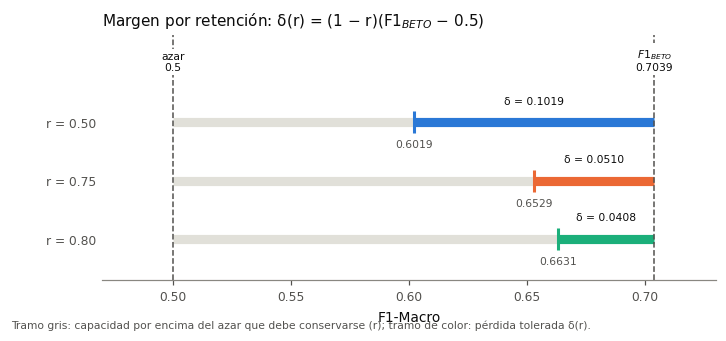

In [2]:
fig, ax = plt.subplots(figsize=(7.2, 2.9))
ys = {0.50: 2, 0.75: 1, 0.80: 0}
for r in R_VALUES:
    y, d = ys[r], DELTA[r]
    thr = F1_BETO - d
    ax.plot([0.5, thr], [y, y], color=style.GRID, lw=6, solid_capstyle='butt')
    ax.plot([thr, F1_BETO], [y, y], color=R_COLOR[r], lw=6, solid_capstyle='butt')
    ax.plot([thr], [y], marker='|', ms=14, color=R_COLOR[r], mew=2)
    ax.text((thr + F1_BETO) / 2, y + 0.28, f'δ = {d:.4f}', ha='center', va='bottom',
            fontsize=style.FONT_SIZES['annot'], color=style.INK)
    ax.text(thr, y - 0.3, f'{thr:.4f}', ha='center', va='top',
            fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY)
for x, lab in ((0.5, 'azar\n0.5'), (F1_BETO, f'$F1_{{BETO}}$\n{F1_BETO:.4f}')):
    ax.axvline(x, color=style.INK_SECONDARY, lw=1, ls='--')
    ax.text(x, 2.85, lab, ha='center', va='bottom', fontsize=style.FONT_SIZES['annot'], color=style.INK,
            bbox=dict(facecolor='white', edgecolor='none', pad=1.5))
ax.set_yticks([ys[r] for r in R_VALUES], [f'r = {r:.2f}' for r in R_VALUES])
ax.set_ylim(-0.7, 3.5)
ax.set_xlim(0.47, 0.73)
ax.set_xlabel('F1-Macro')
ax.spines['left'].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.set_title('Margen por retención: δ(r) = (1 − r)(F1$_{BETO}$ − 0.5)', loc='left')
fig.text(0.01, -0.04, 'Tramo gris: capacidad por encima del azar que debe conservarse (r); tramo de color: pérdida tolerada δ(r).',
         fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY)
print(style.save(fig, FIG / 'fig1_margen_retencion'))
plt.show()

## Figura 2 — P(V1) frente a ρ, formulación B

`malla_escenarios.csv`: línea en el escenario central (discordancia p50, DE 0.010); banda mínimo–máximo sobre los escenarios factibles.

C:\Users\DELL\Desktop\TT\TT2\ttdicevc\results\f11_potencia\figures\fig2_potencia_B.png


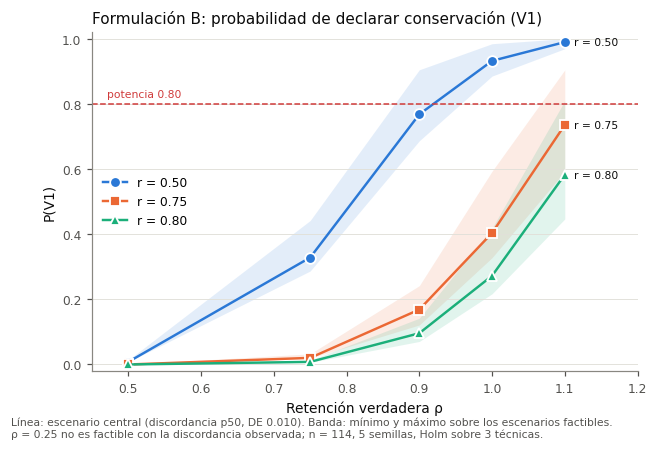

In [3]:
g = MALLA[MALLA.factible & (MALLA.formulacion == 'B')]
fig, ax = plt.subplots(figsize=(6.4, 4.0))
for r in R_VALUES:
    s = g[np.isclose(g.r, r)]
    band = s.groupby('rho').P_V1.agg(['min', 'max'])
    ax.fill_between(band.index, band['min'], band['max'], color=R_COLOR[r], alpha=0.13, lw=0)
    c = central(s).sort_values('rho')
    ax.plot(c.rho, c.P_V1, color=R_COLOR[r], marker=R_MARKER[r], ms=7, mec='white', mew=1.2, label=f'r = {r:.2f}')
    ax.annotate(f'r = {r:.2f}', (c.rho.iloc[-1], c.P_V1.iloc[-1]), xytext=(6, 0), textcoords='offset points',
                va='center', fontsize=style.FONT_SIZES['annot'], color=style.INK)
ax.axhline(0.80, color=style.THRESHOLD_COLOR, lw=1, ls='--')
ax.text(0.47, 0.82, 'potencia 0.80', fontsize=style.FONT_SIZES['annot'], color=style.THRESHOLD_COLOR)
ax.set_xlim(0.45, 1.2)
ax.set_ylim(-0.02, 1.02)
ax.set_xlabel('Retención verdadera ρ')
ax.set_ylabel('P(V1)')
ax.grid(axis='y')
ax.legend(loc='center left')
ax.set_title('Formulación B: probabilidad de declarar conservación (V1)', loc='left')
fig.text(0.01, -0.04, 'Línea: escenario central (discordancia p50, DE 0.010). Banda: mínimo y máximo sobre los escenarios factibles.\n'
         'ρ = 0.25 no es factible con la discordancia observada; n = 114, 5 semillas, Holm sobre 3 técnicas.',
         fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY)
print(style.save(fig, FIG / 'fig2_potencia_B'))
plt.show()

## Figura 3 — P(V1..V4) por ρ en el escenario central, formulación B

`malla_escenarios.csv`. Las celdas no factibles se indican sin barra.

C:\Users\DELL\Desktop\TT\TT2\ttdicevc\results\f11_potencia\figures\fig3_veredictos_central.png


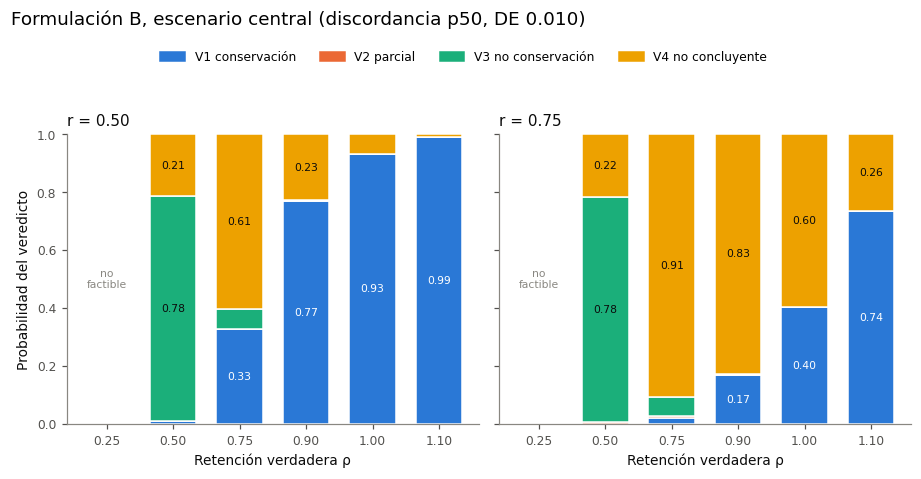

In [4]:
c_all = central(MALLA[MALLA.formulacion == 'B'])
rhos = sorted(MALLA.rho.unique())
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.8), sharey=True)
for ax, r in zip(axes, (0.50, 0.75)):
    s = c_all[np.isclose(c_all.r, r)].set_index('rho')
    x = np.arange(len(rhos))
    for i, rho in enumerate(rhos):
        row = s.loc[rho]
        if not row.factible:
            ax.text(i, 0.5, 'no\nfactible', ha='center', va='center', fontsize=style.FONT_SIZES['annot'],
                    color=style.MUTED)
            continue
        bottom = 0.0
        for v in ('V1', 'V2', 'V3', 'V4'):
            h = row[f'P_{v}']
            ax.bar(i, h, bottom=bottom, width=0.7, color=V_COLOR[v], edgecolor='white', linewidth=1)
            if h >= 0.08:
                ax.text(i, bottom + h / 2, f'{h:.2f}', ha='center', va='center',
                        fontsize=style.FONT_SIZES['annot'], color='white' if v in ('V1', 'V2') else style.INK)
            bottom += h
    ax.set_xticks(x, [f'{v:.2f}' for v in rhos])
    ax.set_xlim(-0.6, len(rhos) - 0.4)
    ax.set_xlabel('Retención verdadera ρ')
    ax.set_title(f'r = {r:.2f}', loc='left')
axes[0].set_ylabel('Probabilidad del veredicto')
axes[0].set_ylim(0, 1)
handles = [Patch(color=V_COLOR[v], label=V_LABEL[v]) for v in ('V1', 'V2', 'V3', 'V4')]
fig.legend(handles=handles, loc='upper center', ncol=4, bbox_to_anchor=(0.5, 1.06))
fig.suptitle('Formulación B, escenario central (discordancia p50, DE 0.010)', x=0.01, ha='left', y=1.13)
fig.tight_layout()
print(style.save(fig, FIG / 'fig3_veredictos_central'))
plt.show()

## Figura 4 — Ancho del IC de Δ en validación

`empirico.csv`, estadístico Δ, α_h = α/3 (IC bilateral al 96.7 %, el nivel más estricto de Holm). Líneas verticales: δ(r) de `canonical_numbers.json`.

C:\Users\DELL\Desktop\TT\TT2\ttdicevc\results\f11_potencia\figures\fig4_ancho_ic_delta.png


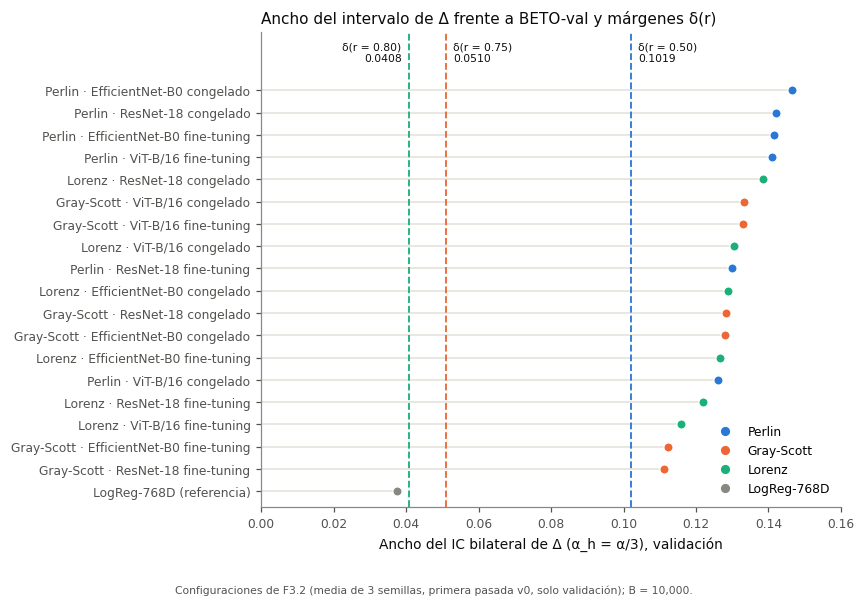

In [5]:
A3 = EMP.alpha_h.min()                     # α/3
d = EMP[(EMP.estadistico == 'delta') & np.isclose(EMP.alpha_h, A3)].copy()
ARCH = {'resnet18': 'ResNet-18', 'efficientnet_b0': 'EfficientNet-B0', 'vit_b_16': 'ViT-B/16', 'logreg': 'LogReg'}
STRAT = {'finetune': 'fine-tuning', 'frozen': 'congelado', 'none': ''}
def label(row):
    if row.technique == 'emb768':
        return 'LogReg-768D (referencia)'
    return f'{style.TECH_LABEL[row.technique]} · {ARCH[row.arch]} {STRAT[row.strategy]}'
d['etiqueta'] = d.apply(label, axis=1)
d = d.sort_values('ancho').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(6.8, 5.6))
for i, row in d.iterrows():
    col = style.MUTED if row.technique == 'emb768' else style.TECH_COLOR[row.technique]
    ax.plot([0, row.ancho], [i, i], color=style.GRID, lw=1)
    ax.plot(row.ancho, i, 'o', color=col, ms=6, mec='white', mew=0.8)
LABEL_POS = {0.80: ('right', -0.002), 0.75: ('left', 0.002), 0.50: ('left', 0.002)}
for r in R_VALUES:
    ax.axvline(DELTA[r], color=R_COLOR[r], lw=1.2, ls='--')
    ha, dx = LABEL_POS[r]
    ax.text(DELTA[r] + dx, len(d) + 0.2, f'δ(r = {r:.2f})\n{DELTA[r]:.4f}', ha=ha, va='bottom',
            fontsize=style.FONT_SIZES['annot'], color=style.INK)
ax.set_yticks(range(len(d)), d.etiqueta)
ax.set_ylim(-0.7, len(d) + 1.6)
ax.set_xlim(0, 0.16)
ax.set_xlabel('Ancho del IC bilateral de Δ (α_h = α/3), validación')
handles = [Line2D([], [], marker='o', ls='', color=style.TECH_COLOR[t], label=style.TECH_LABEL[t]) for t in style.TECH_COLOR]
handles.append(Line2D([], [], marker='o', ls='', color=style.MUTED, label='LogReg-768D'))
ax.legend(handles=handles, loc='lower right')
ax.set_title('Ancho del intervalo de Δ frente a BETO-val y márgenes δ(r)', loc='left')
fig.text(0.01, -0.03, 'Configuraciones de F3.2 (media de 3 semillas, primera pasada v0, solo validación); B = 10,000.',
         fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY)
print(style.save(fig, FIG / 'fig4_ancho_ic_delta'))
plt.show()

## Figura 5 — Discordancia con BETO frente al ancho del IC (H3)

`empirico.csv`: `discordancia_media` (media de las semillas de cada configuración) y ancho del IC de Δ con α_h = α/3.

C:\Users\DELL\Desktop\TT\TT2\ttdicevc\results\f11_potencia\figures\fig5_discordancia_ancho.png


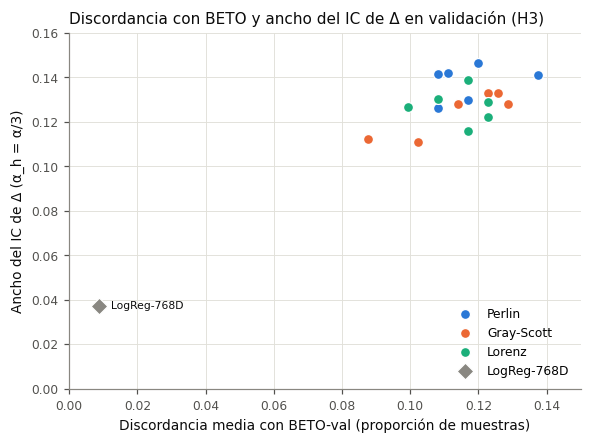

In [6]:
fig, ax = plt.subplots(figsize=(6.0, 4.2))
for t in style.TECH_COLOR:
    s = d[d.technique == t]
    ax.scatter(s.discordancia_media, s.ancho, s=42, color=style.TECH_COLOR[t], edgecolor='white', lw=0.8,
               label=style.TECH_LABEL[t], zorder=3)
ref = d[d.technique == 'emb768'].iloc[0]
ax.scatter(ref.discordancia_media, ref.ancho, s=60, marker='D', color=style.MUTED, edgecolor='white', lw=0.8,
           label='LogReg-768D', zorder=3)
ax.annotate('LogReg-768D', (ref.discordancia_media, ref.ancho), xytext=(8, 0), textcoords='offset points',
            va='center', fontsize=style.FONT_SIZES['annot'], color=style.INK)
ax.set_xlim(0, 0.15)
ax.set_ylim(0, 0.16)
ax.set_xlabel('Discordancia media con BETO-val (proporción de muestras)')
ax.set_ylabel('Ancho del IC de Δ (α_h = α/3)')
ax.grid(True)
ax.legend(loc='lower right')
ax.set_title('Discordancia con BETO y ancho del IC de Δ en validación (H3)', loc='left')
print(style.save(fig, FIG / 'fig5_discordancia_ancho'))
plt.show()

## Figura 6 — Retención mínima detectable, r = 0.50

`retencion_minima.csv`: menor ρ con P(V1) ≥ 0.80 por escenario (discordancia × DE entre semillas), formulaciones A y B.

C:\Users\DELL\Desktop\TT\TT2\ttdicevc\results\f11_potencia\figures\fig6_retencion_minima.png


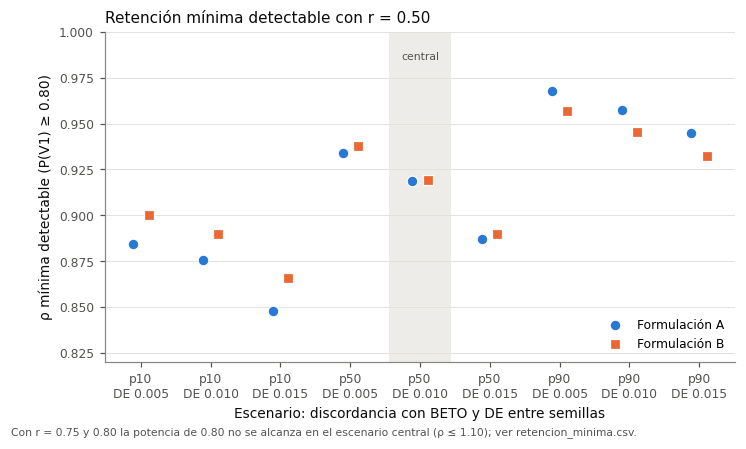

In [7]:
s = RMIN[np.isclose(RMIN.r, 0.50)].copy()
order = [(dl, sd) for dl in ('p10', 'p50', 'p90') for sd in (0.005, 0.010, 0.015)]
FORM_STYLE = {'A': dict(marker='o', color='#2a78d6'), 'B': dict(marker='s', color='#eb6834')}
fig, ax = plt.subplots(figsize=(7.4, 3.9))
for j, form in enumerate(('A', 'B')):
    f = s[s.formulacion == form].set_index(['disc_etiqueta', 'de_objetivo'])
    xs = np.arange(len(order)) + (j - 0.5) * 0.22
    ys = [f.loc[(dl, sd), 'rho_min'] for dl, sd in order]
    ax.plot(xs, ys, ls='', ms=7, mec='white', mew=0.8, label=f'Formulación {form}', **FORM_STYLE[form])
ci = order.index(CENTRAL)
ax.axvspan(ci - 0.45, ci + 0.45, color=style.GRID, alpha=0.6, lw=0, zorder=0)
ax.text(ci, 0.985, 'central', ha='center', fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY)
ax.set_xticks(range(len(order)), [f'{dl}\nDE {sd:.3f}' for dl, sd in order])
ax.set_ylim(0.82, 1.0)
ax.set_ylabel('ρ mínima detectable (P(V1) ≥ 0.80)')
ax.set_xlabel('Escenario: discordancia con BETO y DE entre semillas')
ax.grid(axis='y')
ax.legend(loc='lower right')
ax.set_title('Retención mínima detectable con r = 0.50', loc='left')
fig.text(0.01, -0.06, 'Con r = 0.75 y 0.80 la potencia de 0.80 no se alcanza en el escenario central (ρ ≤ 1.10); ver retencion_minima.csv.',
         fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY)
print(style.save(fig, FIG / 'fig6_retencion_minima'))
plt.show()

## Figura 7 — Distribución bootstrap de θ* (simulación ilustrativa)

**Simulación ilustrativa; sus valores no son cifras del reporte.** Escenario central (ρ = 1.00, discordancia p50, DE 0.010), r = 0.50, formulación B. Los parámetros del generador (a, η, κ) se leen de `malla_escenarios.csv` y las funciones se importan de `potencia.py`:

- cada réplica se evalúa con `pot.simulate_one`, que da el veredicto por técnica;
- para dibujar θ* se reproduce la misma réplica con una copia del generador aleatorio y las funciones `pot.draw_predictions`, `pot.boot_weights`, `pot.f1_macro_weighted` y `pot.holm`, y se comprueba que el veredicto coincide con el de `simulate_one`.

Se recorren réplicas con la semilla fija hasta encontrar una con veredicto V1 y otra con V4 para la técnica 1. El límite usado por Holm es el cuantil α_h de θ*, es decir, el límite inferior del IC bilateral al 1 − 2α_h. V1 exige ese límite > 0 (p ≤ α_h).

In [8]:
SEMILLA_ILUSTRATIVA = 20261102
R_ILUS = 0.50
row = MALLA[(MALLA.rho == 1.0) & (MALLA.disc_etiqueta == 'p50') & np.isclose(MALLA.de_objetivo, 0.010)
            & (MALLA.formulacion == 'B') & np.isclose(MALLA.r, R_ILUS)].iloc[0]
a, eta, kappa = row.a, row.eta, row.kappa

data = pot.load_inputs(pot.Log(Path(os.devnull)))
beto = pot.Beto(data['y_test'], data['beto_test'])
floor = max(v['value']['test'] for k, v in NUM.items() if k.startswith('floor.brightness.'))
rng = np.random.default_rng(SEMILLA_ILUSTRATIVA)
Yp = rng.permuted(np.tile(beto.y, (pot.N_PERM, 1)), axis=1).astype(np.float32)
ri, fi, n = pot.R_VALUES.index(R_ILUS), pot.FORMS.index('B'), len(beto.y)

def theta_boot(rng_copy):
    # Misma secuencia de sorteos que simulate_one: predicciones y luego índices bootstrap
    yhat = pot.draw_predictions(rng_copy, beto, a, eta, kappa, 1)[0]
    P = np.column_stack([np.where(beto.b == 1, beto.y, 1 - beto.y), yhat.reshape(n, -1)])
    W, _ = pot.boot_weights(rng_copy, pot.B_S, n)
    F = pot.f1_macro_weighted(W, beto.y, P)
    vis = F[:, 1:].reshape(pot.B_S, pot.N_TECH, pot.N_SEEDS).mean(axis=2)
    return (vis - pot.F1_AZAR) - R_ILUS * (F[:, :1] - pot.F1_AZAR)

found = {}
for rep in range(500):
    state = rng.bit_generator.state
    verdicts, floor_sup, _, _ = pot.simulate_one(rng, beto, Yp, a, eta, kappa, floor)
    v = pot.VERDICTS[int(np.argmax(verdicts[fi, ri, 0]))]
    if v in ('V1', 'V4') and v not in found:
        rc = np.random.default_rng(); rc.bit_generator.state = state
        th = theta_boot(rc)
        p = (th <= 0).mean(axis=0)
        rej, a_h = pot.holm(p)
        expected = 'V3' if not floor_sup[0] else ('V1' if rej[0] else ('V2' if np.quantile(th[:, 0], 1 - a_h[0]) < 0 else 'V4'))
        assert expected == v, (rep, expected, v)
        found[v] = {'rep': rep, 'theta': th[:, 0], 'alpha_h': a_h[0], 'p': p[0],
                    'li': np.quantile(th[:, 0], a_h[0])}
    if len(found) == 2:
        break
for v, f in found.items():
    print(f"{v}: réplica {f['rep']}, α_h = {f['alpha_h']:.4f}, p = {f['p']:.4f}, límite = {f['li']:+.4f}")

Insumos: y_val [70, 44], y_test [70, 44] (0/1); 54 corridas de F3.2 (solo val)


  sha256 meta/sample_index.csv  74dc778292447c66be60b35b5ec224c53b01433423923fa6d6ddef91749de0f5


  sha256 results/predictions/referencia/text__beto__finetune__seed42.csv  3d3587469545e592e39fa62d3b00b0acd52889bfe21dceb0a5c2816a28f7916e


  sha256 results/predictions/referencia/emb768__logreg__none__seed42.csv  b8c3d471a860b943df962fa8e4652d2ff400e3fcbcf6b9af2e84871091cb778a


  sha256 results/f32_primera_pasada/predictions.csv  448b457f37921ab5549218fb870de1642820305fce0df317ab5d212f2ba515ed


  sha256 results/canonical_numbers.json  81d218e351750d63c74ef76cb92f24ab536e15079f317e7bfaadeccbdc4f151e


V1: réplica 0, α_h = 0.0167, p = 0.0045, límite = +0.0169
V4: réplica 1, α_h = 0.0500, p = 0.0915, límite = -0.0131


C:\Users\DELL\Desktop\TT\TT2\ttdicevc\results\f11_potencia\figures\fig7_theta_bootstrap_ilustrativa.png


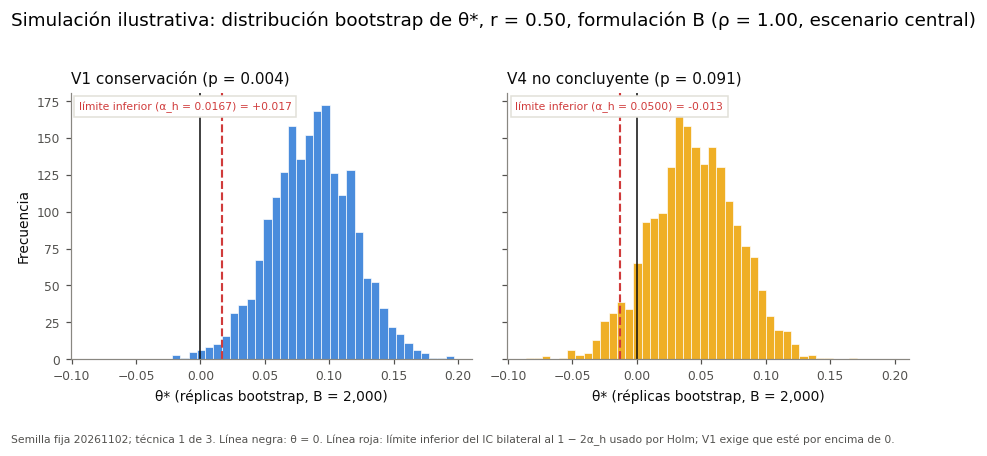

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.6), sharey=True)
bins = np.linspace(min(f['theta'].min() for f in found.values()), max(f['theta'].max() for f in found.values()), 45)
for ax, v in zip(axes, ('V1', 'V4')):
    f = found[v]
    ax.hist(f['theta'], bins=bins, color=V_COLOR[v], alpha=0.85, edgecolor='white', linewidth=0.5)
    ax.axvline(0, color=style.INK, lw=1)
    ax.axvline(f['li'], color=style.THRESHOLD_COLOR, lw=1.4, ls='--')
    ax.text(0.02, 0.97, f"límite inferior (α_h = {f['alpha_h']:.4f}) = {f['li']:+.3f}", transform=ax.transAxes,
            va='top', ha='left', fontsize=style.FONT_SIZES['annot'], color=style.THRESHOLD_COLOR,
            bbox=dict(facecolor='white', edgecolor=style.GRID, pad=3))
    ax.set_title(f'{V_LABEL[v]} (p = {f["p"]:.3f})', loc='left')
    ax.set_xlabel('θ* (réplicas bootstrap, B = 2,000)')
axes[0].set_ylabel('Frecuencia')
fig.suptitle('Simulación ilustrativa: distribución bootstrap de θ*, r = 0.50, formulación B (ρ = 1.00, escenario central)',
             x=0.01, ha='left', y=1.03)
fig.text(0.01, -0.06, f'Semilla fija {SEMILLA_ILUSTRATIVA}; técnica 1 de 3. Línea negra: θ = 0. Línea roja: límite inferior '
         'del IC bilateral al 1 − 2α_h usado por Holm; V1 exige que esté por encima de 0.',
         fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY)
fig.tight_layout()
print(style.save(fig, FIG / 'fig7_theta_bootstrap_ilustrativa'))
plt.show()